In [1]:
# File paths and imports
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from shapely.geometry import mapping
from rasterio.features import geometry_mask, geometry_window, rasterize
from rasterio.windows import transform as window_transform
from rasterio.warp import reproject, Resampling
from scipy.ndimage import label, binary_erosion

project_dir = Path(r'C:\Users\bdhar\OneDrive - Clemson University\GeoAI\Aquaculture')
raster_dir = project_dir / 'Bangladesh_Landcover_Change_Maps_1999_2014_2018_2020_2022'
boundary_dir = project_dir / 'Bangaldesh_BND' / 'GIS_SatkhiraBND' / 'Upazila'

raster_files = {
    1999: raster_dir / 'Bangladesh_Landcover_1999_v3.tif',
    2014: raster_dir / 'Bangladesh_Landcover_2014_v4exp.tif',
    2018: raster_dir / 'Bangladesh_Landcover_2018_v4exp.tif',
    2020: raster_dir / 'Bangladesh_Landcover_2020_v2exp.tif',
    2022: raster_dir / 'Bangladesh_Landcover_2022_v1exp.tif'
}

shyamnagar = gpd.read_file(boundary_dir / 'Shaymnagar_Upazila.shp')
unions = gpd.read_file(boundary_dir / 'Unions_Shyamnagar.shp')

landsat_matches = list(project_dir.rglob('Shyamnagar_Landsat_1999_2014.tif'))
if len(landsat_matches) != 1:
    raise FileNotFoundError('Check the Landsat GeoTIFF location.')
landsat_file = landsat_matches[0]

In [2]:
# Check the land-cover raster grids
with rasterio.open(raster_files[1999]) as ref:
    for year, path in raster_files.items():
        with rasterio.open(path) as src:
            same_grid = (src.shape == ref.shape and src.crs == ref.crs
                         and src.transform == ref.transform)
            print(year, src.res, 'Aligned:', same_grid)
            if not same_grid:
                raise ValueError(f'Raster grid does not match: {path.name}')

1999 (15.0, 15.0) Aligned: True
2014 (15.0, 15.0) Aligned: True
2018 (15.0, 15.0) Aligned: True
2020 (15.0, 15.0) Aligned: True
2022 (15.0, 15.0) Aligned: True


In [3]:
# Pond area and change by union
years = list(raster_files)
periods = list(zip(years[:-1], years[1:]))
results = []

with rasterio.open(raster_files[1999]) as ref:
    union_proj = unions.to_crs(ref.crs)
    pixel_ha = abs(ref.transform.a * ref.transform.e) / 10000

    for _, row in union_proj.iterrows():
        geom = [mapping(row.geometry)]
        window = geometry_window(ref, geom)
        transform = window_transform(window, ref.transform)

        inside = geometry_mask(
            geom,
            out_shape=(int(window.height), int(window.width)),
            transform=transform,
            invert=True
        )

        maps = {}
        for year, path in raster_files.items():
            with rasterio.open(path) as src:
                maps[year] = src.read(1, window=window)

        # Shared mapped pixels for all five years
        valid = inside.copy()
        for year in years:
            valid &= maps[year] != 0

        result = {'Union': row['shapeName']}

        for year in years:
            result[f'{year}_ha'] = ((maps[year] == 3) & valid).sum() * pixel_ha

        for start, end in periods:
            a, b = maps[start], maps[end]

            result[f'New_{start}_{end}_ha'] = (
                valid & (a != 3) & (b == 3)
            ).sum() * pixel_ha

            result[f'Lost_{start}_{end}_ha'] = (
                valid & (a == 3) & (b != 3)
            ).sum() * pixel_ha

        results.append(result)

pond_table = pd.DataFrame(results)
pond_table['Net_1999_2022_ha'] = pond_table['2022_ha'] - pond_table['1999_ha']

display(pond_table.sort_values('Net_1999_2022_ha', ascending=False).round(2))

,Union,1999_ha,2014_ha,2018_ha,2020_ha,2022_ha,New_1999_2014_ha,Lost_1999_2014_ha,New_2014_2018_ha,Lost_2014_2018_ha,New_2018_2020_ha,Lost_2018_2020_ha,New_2020_2022_ha,Lost_2020_2022_ha,Net_1999_2022_ha
14,Padma Pukur,1633.43,2942.17,2941.09,2941.09,2941.09,1310.40,1.66,0.27,1.35,0.00,0.0,0.0,0.0,1307.66
7,Kashimari,657.74,1694.77,1720.87,1733.58,1733.58,1039.25,2.23,26.10,0.00,12.71,0.0,0.0,0.0,1075.84
4,Gabura,1525.07,2568.15,2568.51,2600.05,2600.05,1043.84,0.76,0.36,0.00,31.54,0.0,0.0,0.0,1074.98
0,Atulia,1299.64,2120.90,2125.42,2125.42,2125.42,851.15,29.90,4.57,0.04,0.00,0.0,0.0,0.0,825.77
2,Buri Goalini,2008.08,2816.01,2810.81,2810.81,2810.81,886.59,78.66,1.19,6.39,0.00,0.0,0.0,0.0,802.73
16,Ramjan Nagar,1566.94,2273.00,2272.54,2272.54,2272.54,729.74,23.69,0.11,0.56,0.00,0.0,0.0,0.0,705.60
5,Ishwaripur,976.00,1643.80,1644.28,1670.58,1670.58,668.05,0.25,0.47,0.00,26.30,0.0,0.0,0.0,694.58
19,Shyamnagar,803.54,1399.75,1433.68,1433.68,1433.68,598.48,2.27,33.95,0.02,0.00,0.0,0.0,0.0,630.14
12,Munshiganj,2025.34,2603.50,2605.50,2608.20,2608.20,637.45,59.29,2.05,0.04,2.70,0.0,0.0,0.0,582.86
13,Nurnagar,1018.84,1599.12,1599.44,1599.44,1599.44,582.91,2.63,0.32,0.00,0.00,0.0,0.0,0.0,580.59


In [4]:
# Change by period

periods = [(1999, 2014), (2014, 2018),
           (2018, 2020), (2020, 2022)]

summary = []

for start, end in periods:
    new = pond_table[f'New_{start}_{end}_ha'].sum()
    lost = pond_table[f'Lost_{start}_{end}_ha'].sum()

    summary.append({
        'Period': f'{start}-{end}',
        'New ponds (ha)': new,
        'Lost ponds (ha)': lost,
        'Net change (ha)': new - lost,
        'Annual net change (ha/yr)': (new - lost) / (end - start)
    })

period_summary = pd.DataFrame(summary)
display(period_summary.round(2))

,Period,New ponds (ha),Lost ponds (ha),Net change (ha),Annual net change (ha/yr)
0,1999-2014,9121.77,342.02,8779.75,585.32
1,2014-2018,69.50,20.47,49.03,12.26
2,2018-2020,73.26,0.00,73.26,36.63
3,2020-2022,0.00,0.00,0.00,0.00


In [5]:
# Check differences between 2020 and 2022
with rasterio.open(raster_files[2020]) as src20, rasterio.open(raster_files[2022]) as src22:
    geom = [mapping(unions.to_crs(src20.crs).union_all())]

    window = geometry_window(src20, geom)
    transform = window_transform(window, src20.transform)

    inside = geometry_mask(
        geom, (int(window.height), int(window.width)),
        transform, invert=True
    )

    a = src20.read(1, window=window)
    b = src22.read(1, window=window)

    valid = inside & (a != 0) & (b != 0)

    print('Valid pixels:', valid.sum())
    print('Changed pixels:', (valid & (a != b)).sum())
    print('Changed pond pixels:', (valid & ((a == 3) != (b == 3))).sum())
    print('Identical classifications (%):',
          round(100 * (a[valid] == b[valid]).mean(), 2))

Valid pixels: 6860106
Changed pixels: 4084
Changed pond pixels: 0
Identical classifications (%): 99.94


In [6]:
# Source classes of new ponds
periods = [(1999, 2014), (2018, 2020)]

with rasterio.open(raster_files[1999]) as src:
    geom = [mapping(unions.to_crs(src.crs).union_all())]
    window = geometry_window(src, geom)
    trans = window_transform(window, src.transform)

    inside = geometry_mask(
        geom, (int(window.height), int(window.width)),
        trans, invert=True
    )

for start, end in periods:
    with rasterio.open(raster_files[start]) as src1, rasterio.open(raster_files[end]) as src2:
        a = src1.read(1, window=window)
        b = src2.read(1, window=window)

    valid = inside & (a != 0) & (b != 0)
    new_pond = valid & (a != 3) & (b == 3)

    print(f'\n{start}–{end}')
    for code, name in [(1, 'Mangrove'), (2, 'Wetland'),
                       (4, 'Water'), (5, 'Other land')]:
        pixels = (new_pond & (a == code)).sum()
        print(name, ':', pixels, 'pixels')


1999–2014
Mangrove : 389 pixels
Wetland : 0 pixels
Water : 0 pixels
Other land : 405023 pixels

2018–2020
Mangrove : 0 pixels
Wetland : 0 pixels
Water : 0 pixels
Other land : 3256 pixels


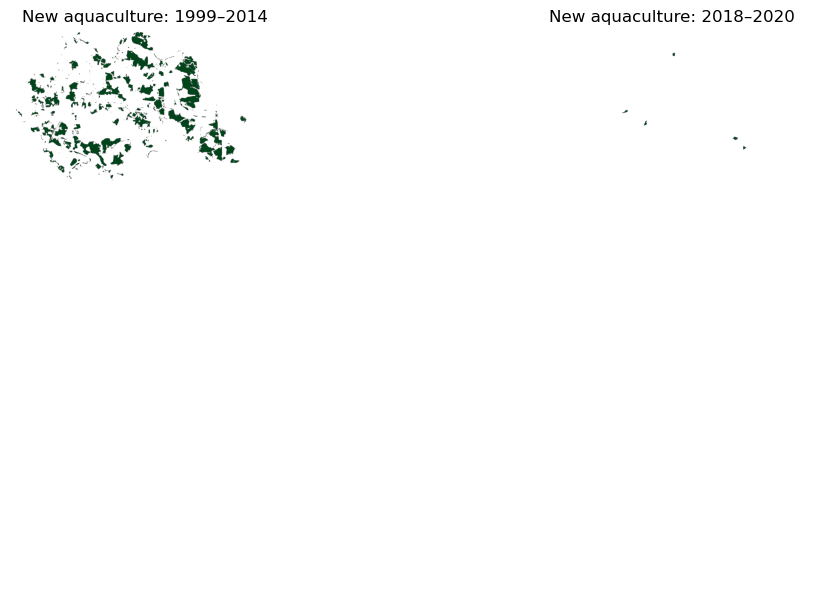

In [7]:
# Map new aquaculture
fig, ax = plt.subplots(1, 2, figsize=(13, 6))

for i, (start, end) in enumerate([(1999, 2014), (2018, 2020)]):

    with rasterio.open(raster_files[start]) as src:
        before = src.read(1, window=window)

    with rasterio.open(raster_files[end]) as src:
        after = src.read(1, window=window)

    valid = inside & (before != 0) & (after != 0)
    new_ponds = valid & (before != 3) & (after == 3)

    image = np.ma.masked_where(~new_ponds, new_ponds)

    ax[i].imshow(image, cmap='Greens', vmin=0, vmax=1)
    ax[i].set_title(f'New aquaculture: {start}–{end}')
    ax[i].axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Check new pond patch sizes
summary = []

for start, end in [(1999, 2014), (2018, 2020)]:
    with rasterio.open(raster_files[start]) as src:
        before = src.read(1, window=window)

    with rasterio.open(raster_files[end]) as src:
        after = src.read(1, window=window)

    new_ponds = inside & (before != 0) & (after != 0) & (before != 3) & (after == 3)

    patches, n = label(new_ponds)
    sizes = np.bincount(patches.ravel())[1:]

    summary.append({
        'Period': f'{start}-{end}',
        'New pond pixels': int(new_ponds.sum()),
        'Total patches': n,
        'Patches >= 9 pixels': int((sizes >= 9).sum()),
        'Area in larger patches (ha)': round(sizes[sizes >= 9].sum() * 0.0225, 2),
        'Largest patch (ha)': round(sizes.max() * 0.0225, 2) if len(sizes) else 0
    })

display(pd.DataFrame(summary))

,Period,New pond pixels,Total patches,Patches >= 9 pixels,Area in larger patches (ha),Largest patch (ha)
0,1999-2014,405412,1046,432,9090.09,798.59
1,2018-2020,3256,6,5,73.24,19.69


In [9]:
# Check the Landsat export
with rasterio.open(landsat_file) as src:
    print('Shape:', src.shape)
    print('Bands:', src.count)
    print('CRS:', src.crs)
    print('Resolution:', src.res)
    print('NoData:', src.nodata)
    print('Band names:', src.descriptions)

    print('Valid pixels:', np.sum(src.dataset_mask() > 0))

Shape: (2787, 1295)
Bands: 12
CRS: EPSG:32645
Resolution: (30.0, 30.0)
NoData: None
Band names: ('Blue_1999', 'Green_1999', 'Red_1999', 'NIR_1999', 'SWIR1_1999', 'SWIR2_1999', 'Blue_2014', 'Green_2014', 'Red_2014', 'NIR_2014', 'SWIR1_2014', 'SWIR2_2014')
Valid pixels: 3609165


In [10]:
# Align Clark labels to the Landsat grid
labels = {}

with rasterio.open(landsat_file) as landsat:
    shape = landsat.shape
    dst_crs = landsat.crs
    dst_transform = landsat.transform

    for year in [1999, 2014]:
        with rasterio.open(raster_files[year]) as src:
            aligned = np.zeros(shape, dtype=np.uint8)

            reproject(
                source=rasterio.band(src, 1),
                destination=aligned,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=dst_transform,
                dst_crs=dst_crs,
                src_nodata=0,
                dst_nodata=0,
                resampling=Resampling.nearest
            )

            labels[year] = aligned

for year in labels:
    print(year, labels[year].shape, np.unique(labels[year]))

1999 (2787, 1295) [0 1 3 4 5]
2014 (2787, 1295) [0 1 3 4 5]


In [11]:
# Classify 1999–2014 pond changes
a = labels[1999]
b = labels[2014]

valid_labels = (a != 0) & (b != 0)

change = np.full(a.shape, 255, dtype=np.uint8)

change[valid_labels & (a != 3) & (b != 3)] = 0
change[valid_labels & (a == 3) & (b == 3)] = 1
change[valid_labels & (a != 3) & (b == 3)] = 2
change[valid_labels & (a == 3) & (b != 3)] = 3

In [12]:
# Keep mapped pixels inside Shyamnagar
with rasterio.open(landsat_file) as src:
    boundary = shyamnagar.to_crs(src.crs)
    aoi_mask = geometry_mask(
        [mapping(g) for g in boundary.geometry],
        out_shape=src.shape,
        transform=src.transform,
        invert=True
    )

    images = src.read().astype(np.float32)
    image_valid = np.all(np.isfinite(images), axis=0)
    image_valid &= np.any(images[:6] != 0, axis=0)
    image_valid &= np.any(images[6:] != 0, axis=0)
    pixel_ha = abs(src.transform.a * src.transform.e) / 10000

valid = aoi_mask & valid_labels & image_valid
change[~valid] = 255

names = ['Unchanged non-pond', 'Persistent pond', 'New pond', 'Lost pond']
for code, name in enumerate(names):
    pixels = (change == code).sum()
    print(name, pixels, 'pixels', round(pixels * pixel_ha, 2), 'ha')
print('Valid pixels:', valid.sum())

Unchanged non-pond 1441426 pixels 129728.34 ha
Persistent pond 170009 pixels 15300.81 ha
New pond 101318 pixels 9118.62 ha
Lost pond 3800 pixels 342.0 ha
Valid pixels: 1716553


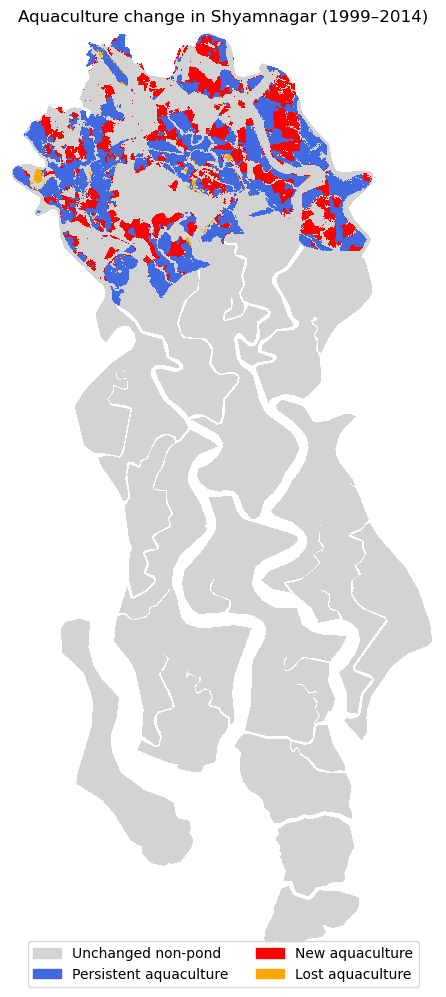

In [13]:
# Map 1999–2014 pond transitions
colors = ['lightgray', 'royalblue', 'red', 'orange']
cmap = ListedColormap(colors)

change_map = np.ma.masked_where(change == 255, change)

plt.figure(figsize=(8, 10))
plt.imshow(change_map, cmap=cmap, vmin=0, vmax=3, interpolation='nearest')
plt.title('Aquaculture change in Shyamnagar (1999–2014)')
plt.axis('off')

from matplotlib.patches import Patch

legend = [
    Patch(color='lightgray', label='Unchanged non-pond'),
    Patch(color='royalblue', label='Persistent aquaculture'),
    Patch(color='red', label='New aquaculture'),
    Patch(color='orange', label='Lost aquaculture')
]

plt.legend(handles=legend, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=2)
plt.tight_layout()
plt.show()

In [14]:
# New pond area by union at 30 m
with rasterio.open(landsat_file) as src:
    union_proj = unions.to_crs(src.crs)

    shapes = [
        (geom, i + 1)
        for i, geom in enumerate(union_proj.geometry)
    ]

    union_grid = rasterize(
        shapes,
        out_shape=src.shape,
        transform=src.transform,
        fill=0,
        dtype='int16'
    )

rows = []

for i, row in unions.reset_index(drop=True).iterrows():
    area = union_grid == i + 1

    rows.append({
        'Union': row['shapeName'],
        'Valid pixels': int((area & valid).sum()),
        'New pond pixels': int((area & (change == 2)).sum()),
        'Persistent pixels': int((area & (change == 1)).sum()),
        'New pond (ha)': (area & (change == 2)).sum() * pixel_ha
    })

union_change = pd.DataFrame(rows)
display(union_change.sort_values('New pond pixels', ascending=False).round(2))

,Union,Valid pixels,New pond pixels,Persistent pixels,New pond (ha)
14,Padma Pukur,44752,14576,18162,1311.84
4,Gabura,45817,11556,16979,1040.04
7,Kashimari,37695,11538,7293,1038.42
2,Buri Goalini,47334,9856,21444,887.04
0,Atulia,47386,9444,14131,849.96
16,Ramjan Nagar,41356,8134,17175,732.06
5,Ishwaripur,46448,7393,10850,665.37
12,Munshiganj,55194,7100,21911,639.00
6,Kaikhali,47091,6735,14513,606.15
19,Shyamnagar,34789,6669,8886,600.21


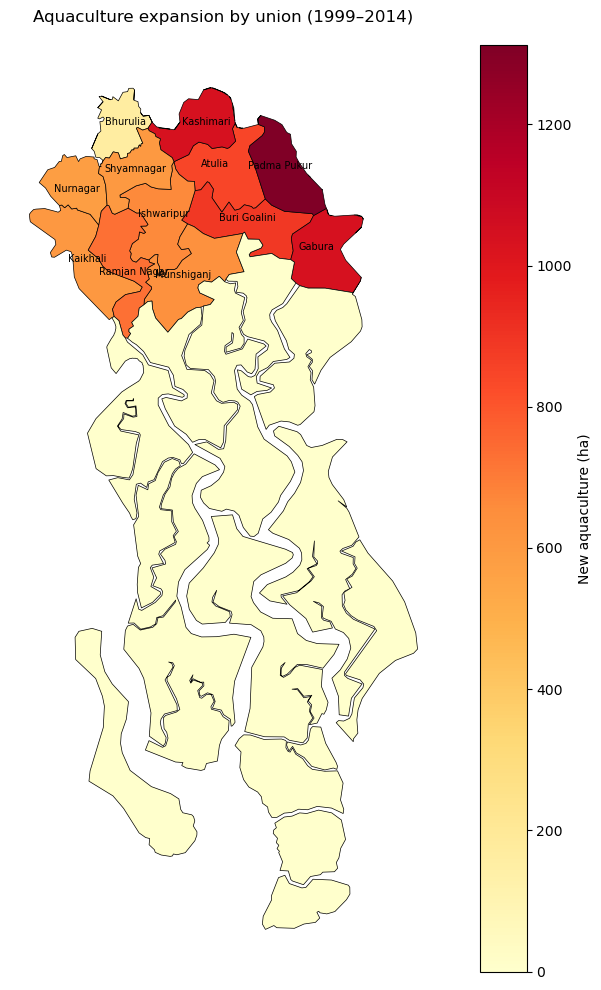

In [15]:
# Map union-level expansion
union_map = union_proj.copy()
union_map['New_ha'] = union_change['New pond (ha)'].values

fig, ax = plt.subplots(figsize=(9, 10))

union_map.plot(
    column='New_ha',
    ax=ax,
    cmap='YlOrRd',
    legend=True,
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={'label': 'New aquaculture (ha)'}
)

for _, row in union_map.iterrows():
    if row['New_ha'] > 100:
        p = row.geometry.representative_point()
        ax.text(p.x, p.y, row['shapeName'], fontsize=7, ha='center')

ax.set_title('Aquaculture expansion by union (1999–2014)')
ax.axis('off')

plt.tight_layout()
plt.show()

In [16]:
# Training, validation and test unions
split = np.zeros(change.shape, dtype=np.uint8)

for i, row in unions.reset_index(drop=True).iterrows():
    name = row['shapeName'].strip().lower()
    area = (union_grid == i + 1) & valid

    if name == 'gabura':
        split[area] = 3
    elif name == 'kashimari':
        split[area] = 2
    elif name != 'satkhira range' and area.sum() > 1000:
        split[area] = 1

# Leave a two-pixel gap between regions
for code in [1, 2, 3]:
    area = split == code
    interior = binary_erosion(area, iterations=2)
    split[area & ~interior] = 0

names = {1: 'Training', 2: 'Validation', 3: 'Testing'}

for code, name in names.items():
    area = split == code
    print(name,
          '| Valid pixels:', area.sum(),
          '| New pond pixels:', ((change == 2) & area).sum())

Training | Valid pixels: 415280 | New pond pixels: 77735
Validation | Valid pixels: 36011 | New pond pixels: 11176
Testing | Valid pixels: 44118 | New pond pixels: 11548


In [17]:
# Prepare the inputs for Colab
X_temporal = np.moveaxis(images, 0, -1)
y = (change == 2).astype(np.float32)
X_temporal[~image_valid] = 0

print('Input:', X_temporal.shape)
print('Labels:', y.shape)
print('Split:', split.shape)

Input: (2787, 1295, 12)
Labels: (2787, 1295)
Split: (2787, 1295)


In [18]:
# Save model inputs for Colab
output_dir = Path(r'C:\Users\bdhar\OneDrive - Clemson University\GeoAI\Aquaculture\Model_Inputs')
output_dir.mkdir(parents=True, exist_ok=True)

np.save(output_dir / 'landsat_1999_2014.npy', X_temporal)
np.save(output_dir / 'new_pond_labels.npy', y)
np.save(output_dir / 'spatial_split.npy', split)

print('Saved model inputs to:', output_dir)

Saved model inputs to: C:\Users\bdhar\OneDrive - Clemson University\GeoAI\Aquaculture\Model_Inputs
